# Random Forest Klassifikation für KHK / Herzinfarkt (CHD/MI)
### Foundations of Data Science — Gruppenprojekt (NHANES 2021–2023)
**Autor:** Marco (Assignment: Random Forest)

---

## 1. Forschungsfrage und Zielsetzung
Verbessern die systemischen Entzündungsmarker **NLR (Neutrophil-to-Lymphocyte Ratio)** und **hs-CRP (High-Sensitivity C-Reactive Protein)** die Vorhersage und Diskrimination von koronarer Herzkrankheit bzw. Myokardinfarkt (CHD/MI) **über etablierte kardiovaskuläre Risikofaktoren hinaus**?

### Warum Random Forest? (Vorlesung Woche 7)
Ein **Random Forest** ist ein Ensemble-Modell aus vielen einzelnen **Entscheidungsbäumen (Decision Trees)**:
1. **Nichtlinearität & Interaktionen:** Er kann komplexe, nichtlineare Zusammenhänge und Wechselwirkungen zwischen Risikofaktoren erfassen, ohne dass wir diese manuell vorgeben müssen.
2. **Bagging (Bootstrap Aggregation):** Jeder Baum wird auf einer zufälligen Stichprobe mit Zurücklegen trainiert. Das senkt die Varianz drastisch gegenüber einem einzelnen überangepassten Baum.
3. **Zufällige Feature-Auswahl (Random Subspace):** An jedem Split wird nur eine zufällige Teilmenge an Variablen betrachtet (`max_features='sqrt'`). Dadurch werden die Bäume dekorreliert.
4. **Mehrheitsentscheid / Mittelung:** Alle 300 Bäume stimmen ab, und der Durchschnitt ihrer Voten ergibt die vorhergesagte Wahrscheinlichkeit.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Pfad zum Projekt-Root
ROOT = Path.cwd().parents[1] if Path.cwd().name == "marco" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from prepare_data import CONFIG, load_data

OUT = ROOT / "notebooks" / "marco" / "results"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = CONFIG["random_state"]
print(f"Setup abgeschlossen! Random Seed: {SEED}")

Setup abgeschlossen! Random Seed: 42


## 2. Daten laden und Feature-Sets definieren
Wir nutzen denselben festen 80/20 Train/Test-Split wie die gesamte Gruppe:
- **Train-Set:** $n=3{,}635$ Probanden (270 Fälle, 7.4%)
- **Test-Set:** $n=909$ Probanden (67 Fälle, 7.4%)

Die hierarchisch geschachtelten Modelle:
- **M0:** Basis-Demographie (`age`, `male`)
- **M1:** Soziodemographie (`M0` + `bmi`, `race_eth`, `income_pir`)
- **M2:** Etablierte Risikofaktoren (`M1` + `smoking`, `diabetes`, `hypertension`, `total_chol`, `hdl_chol`, `egfr`)
- **M2 + NLR:** `M2` + log-transformiertes NLR
- **M2 + CRP:** `M2` + log-transformiertes hs-CRP
- **M3 (Vollmodell):** `M2` + beide Entzündungsmarker (`log_nlr`, `log_crp`)
- **Sensitivitätsmodelle ohne Cholesterin:** `M2 no chol` und `M3 no chol`

In [2]:
M0 = ["age", "male"]
M1 = M0 + ["bmi", "race_eth", "income_pir"]
M2 = M1 + ["smoking", "diabetes", "hypertension", "total_chol", "hdl_chol", "egfr"]
CHOLESTEROL = ["total_chol", "hdl_chol"]
M2_NO_CHOL = [f for f in M2 if f not in CHOLESTEROL]

FEATURE_SETS = {
    "M0": M0,
    "M1": M1,
    "M2": M2,
    "M2 + NLR": M2 + ["log_nlr"],
    "M2 + CRP": M2 + ["log_crp"],
    "M3": M2 + ["log_nlr", "log_crp"],
    "M2 no chol": M2_NO_CHOL,
    "M3 no chol": M2_NO_CHOL + ["log_nlr", "log_crp"],
}
CATEGORICAL = ["race_eth", "smoking"]
BINARY = ["male", "diabetes", "hypertension"]
OUTCOME = "chd_mi"

train, test = load_data(split=True)
y_train, y_test = train[OUTCOME].astype(int), test[OUTCOME].astype(int)
print(f"Train n={len(train)} (Fälle: {y_train.sum()} = {y_train.mean():.1%})")
print(f"Test  n={len(test)} (Fälle: {y_test.sum()} = {y_test.mean():.1%})")

Train n=3635 (Fälle: 270 = 7.4%)
Test  n=909 (Fälle: 67 = 7.4%)


## 3. Geladene Hyperparameter aus der 5-Fold Cross-Validation
Die besten Parameter wurden mit erschöpfendem **GridSearchCV** (`n_estimators=300`, `class_weight=None`, 40 Kandidaten × 5 Stratified Folds = 200 Fits pro Feature-Set) ausschliesslich auf dem Trainings-Set ermittelt:

In [3]:
cv_results = pd.read_csv(OUT / "cv_results.csv")
print("=== 5-Fold CV Beste Hyperparameter (class_weight=None) ===")
display(cv_results.round(4))

cv_delta = pd.read_csv(OUT / "cv_delta_auc.csv")
print("\n=== Trainings Out-of-Fold Delta-AUC ===")
display(cv_delta.round(4))

=== 5-Fold CV Beste Hyperparameter (class_weight=None) ===


,features,max_depth,min_samples_leaf,max_features,class_weight,cv_auc_mean,cv_auc_sd
0,M0,4.0,50,sqrt,NaN,0.7921,0.0098
1,M1,4.0,50,0.5,NaN,0.8043,0.0078
2,M2,12.0,50,sqrt,NaN,0.8584,0.0116
3,M2 + NLR,4.0,5,sqrt,NaN,0.8612,0.0122
4,M2 + CRP,12.0,50,sqrt,NaN,0.8585,0.0123
5,M3,NaN,50,sqrt,NaN,0.8607,0.0135
6,M2 no chol,6.0,50,sqrt,NaN,0.8365,0.0216
7,M3 no chol,4.0,20,sqrt,NaN,0.8370,0.0207



=== Trainings Out-of-Fold Delta-AUC ===


,comparison,auc_a_oof,auc_b_oof,delta_auc_oof
0,M2 + NLR vs M2,0.8596,0.8574,0.0023
1,M2 + CRP vs M2,0.8577,0.8574,0.0003
2,M3 vs M2,0.8602,0.8574,0.0028
3,M3 no chol vs M2 no chol,0.8359,0.8355,0.0004


## 4. Test-Performance, Schwellenwert & Sensitivitätsanalysen
Ergebnisse auf dem unabhängigen Test-Set ($n=909$) mit 1.000 Bootstrap-Resamples für 95%-Konfidenzintervalle, Youden-Threshold aus Training-OOF sowie Vergleich mit `class_weight='balanced_subsample'`:

In [4]:
test_perf = pd.read_csv(OUT / "test_performance.csv")
print("=== Test-Performance aller Feature-Sets ===")
display(test_perf.round(4))

delta_auc = pd.read_csv(OUT / "delta_auc.csv")
print("\n=== Mehrwert der Marker (Delta-AUC mit 95% Bootstrap CI) ===")
display(delta_auc.round(4))

thr_m3 = pd.read_csv(OUT / "threshold_metrics_m3.csv")
print("\n=== M3 Klinische Kennzahlen (Training-OOF Youden-Schwelle) ===")
display(thr_m3.round(4))

cw_sens = pd.read_csv(OUT / "class_weight_sensitivity.csv")
print("\n=== Sensitivität: class_weight=None vs. balanced_subsample ===")
display(cw_sens.round(4))

=== Test-Performance aller Feature-Sets ===


,features,roc_auc,pr_auc,brier,roc_auc_lo,roc_auc_hi,pr_auc_lo,pr_auc_hi,brier_lo,brier_hi,brier_null
0,M0,0.8195,0.1987,0.0622,0.7797,0.8573,0.1497,0.2671,0.0503,0.0746,0.0683
1,M1,0.8270,0.2162,0.0617,0.7870,0.8634,0.1619,0.2977,0.0493,0.0742,0.0683
2,M2,0.8824,0.4134,0.0563,0.8425,0.9161,0.3098,0.5461,0.0450,0.0672,0.0683
3,M2 + NLR,0.8854,0.4191,0.0563,0.8462,0.9219,0.3082,0.5404,0.0448,0.0675,0.0683
4,M2 + CRP,0.8811,0.4076,0.0565,0.8406,0.9159,0.3020,0.5370,0.0451,0.0678,0.0683
5,M3,0.8868,0.4330,0.0563,0.8472,0.9207,0.3250,0.5516,0.0449,0.0675,0.0683
6,M2 no chol,0.8593,0.3431,0.0587,0.8191,0.8967,0.2484,0.4694,0.0471,0.0700,0.0683
7,M3 no chol,0.8578,0.3672,0.0586,0.8156,0.8975,0.2661,0.4980,0.0467,0.0703,0.0683



=== Mehrwert der Marker (Delta-AUC mit 95% Bootstrap CI) ===


,comparison,delta_auc,lo,hi,p_boot_le_0
0,M2 + NLR vs M2,0.0030,-0.0065,0.0132,0.278
1,M2 + CRP vs M2,-0.0013,-0.0044,0.0017,0.809
2,M3 vs M2,0.0044,-0.0051,0.0141,0.149
3,M3 no chol vs M2 no chol,-0.0015,-0.0114,0.0081,0.598
4,M2 vs M2 no chol,0.0231,0.0003,0.0443,0.024



=== M3 Klinische Kennzahlen (Training-OOF Youden-Schwelle) ===


,threshold,metric,value,lo,hi
0,0.0883,sensitivity,0.8657,0.7820,0.9455
1,0.0883,specificity,0.7423,0.7104,0.7694
2,0.0883,ppv,0.2109,0.1655,0.2614
3,0.0883,npv,0.9858,0.9762,0.9941



=== Sensitivität: class_weight=None vs. balanced_subsample ===


,features,class_weight,cv_auc,test_roc_auc,test_pr_auc,test_brier
0,M2,NaN,0.8584,0.8824,0.4134,0.0563
1,M2,balanced_subsample,0.8587,0.8916,0.4159,0.1067
2,M3,NaN,0.8607,0.8868,0.4330,0.0563
3,M3,balanced_subsample,0.8613,0.8921,0.4231,0.0814


## 5. Permutation Feature Importance
Welche Variablen beeinflussen die Entscheidungen des Random Forest am stärksten?

In [5]:
imp = pd.read_csv(OUT / "permutation_importance_m3.csv").sort_values("auc_drop_mean", ascending=False)
display(imp.round(4))

,feature,auc_drop_mean,auc_drop_sd
12,total_chol,0.0390,0.0079
11,age,0.0346,0.0113
10,egfr,0.0174,0.0063
9,hypertension,0.0143,0.0066
8,diabetes,0.0117,0.0047
7,smoking,0.0076,0.0051
6,hdl_chol,0.0054,0.0019
5,log_nlr,0.0044,0.0022
4,male,0.0042,0.0013
3,income_pir,0.0032,0.0011


## 6. Generierte Publikations-Abbildungen anzeigen

1. Diskrimination nach Feature-Set:


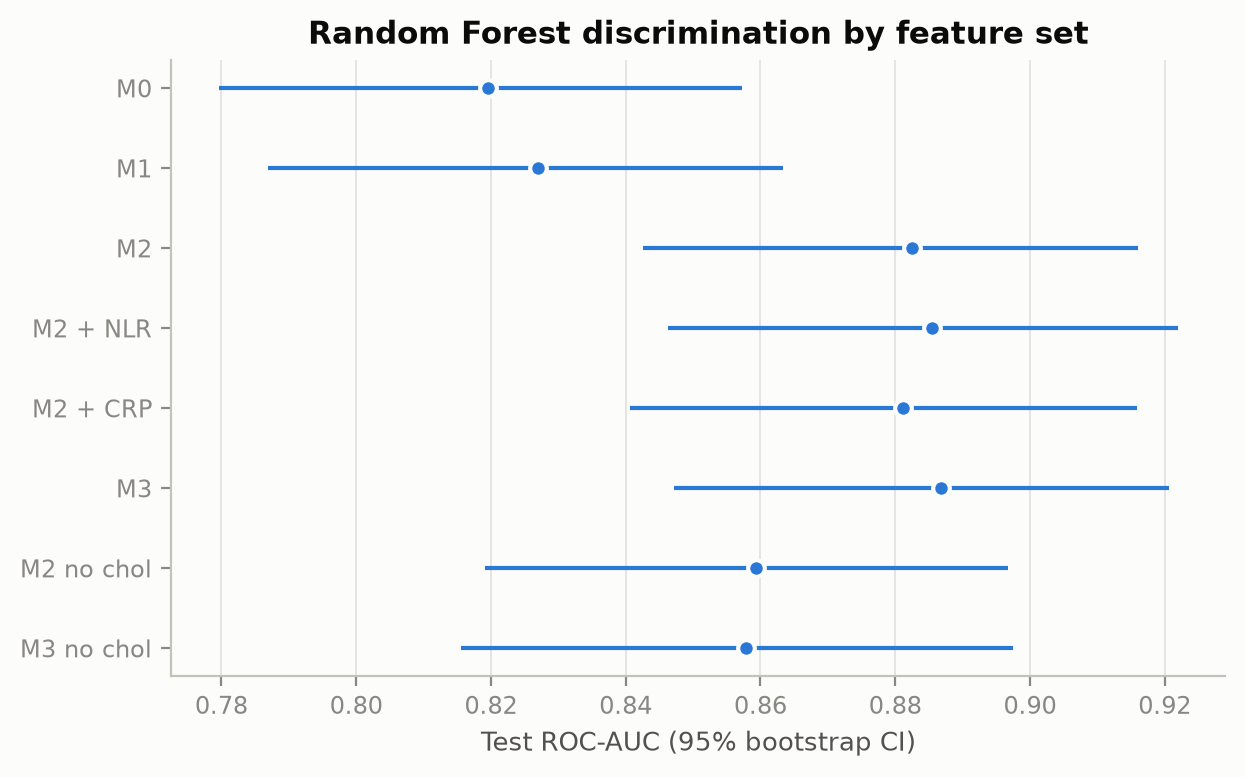

2. ROC- und Precision-Recall-Kurven (M2 vs. M3):


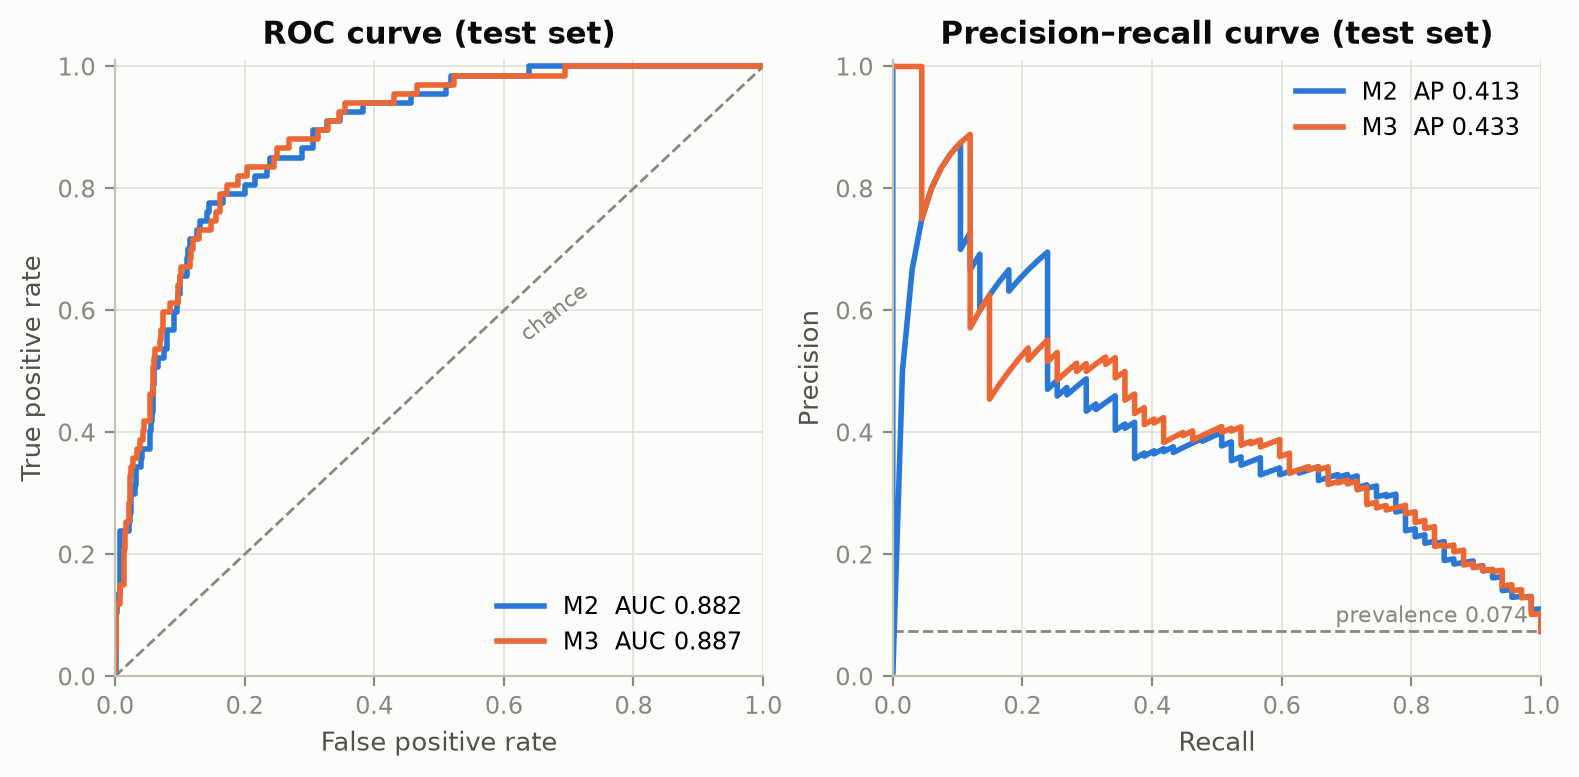

3. Kalibrierung M3 vs. Nullmodell:


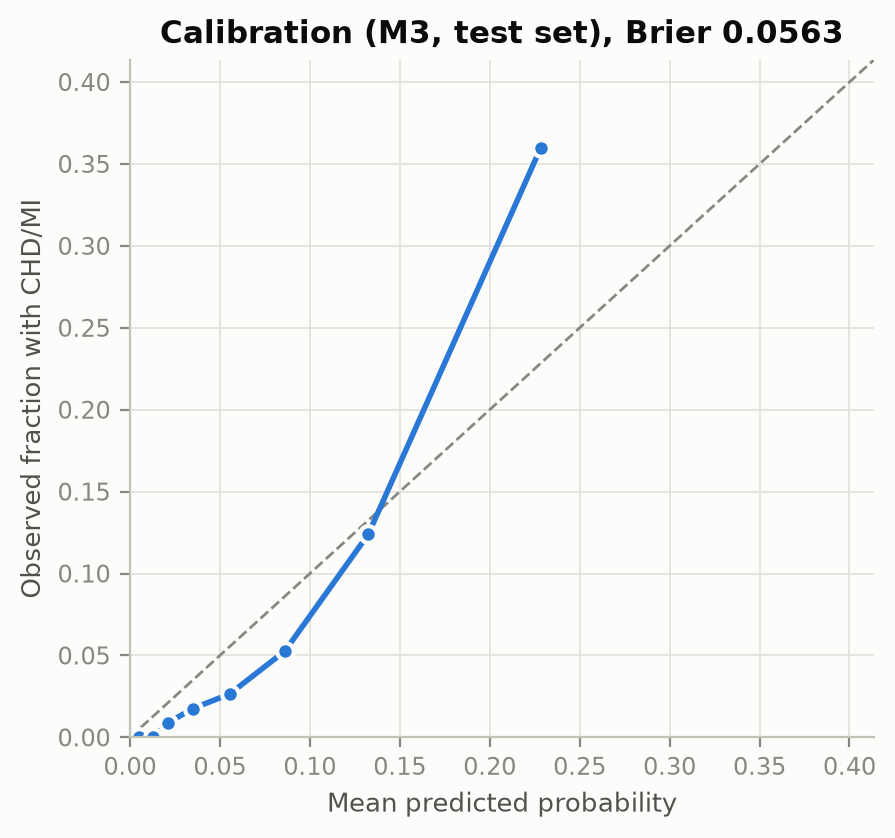

4. Permutation Feature Importance:


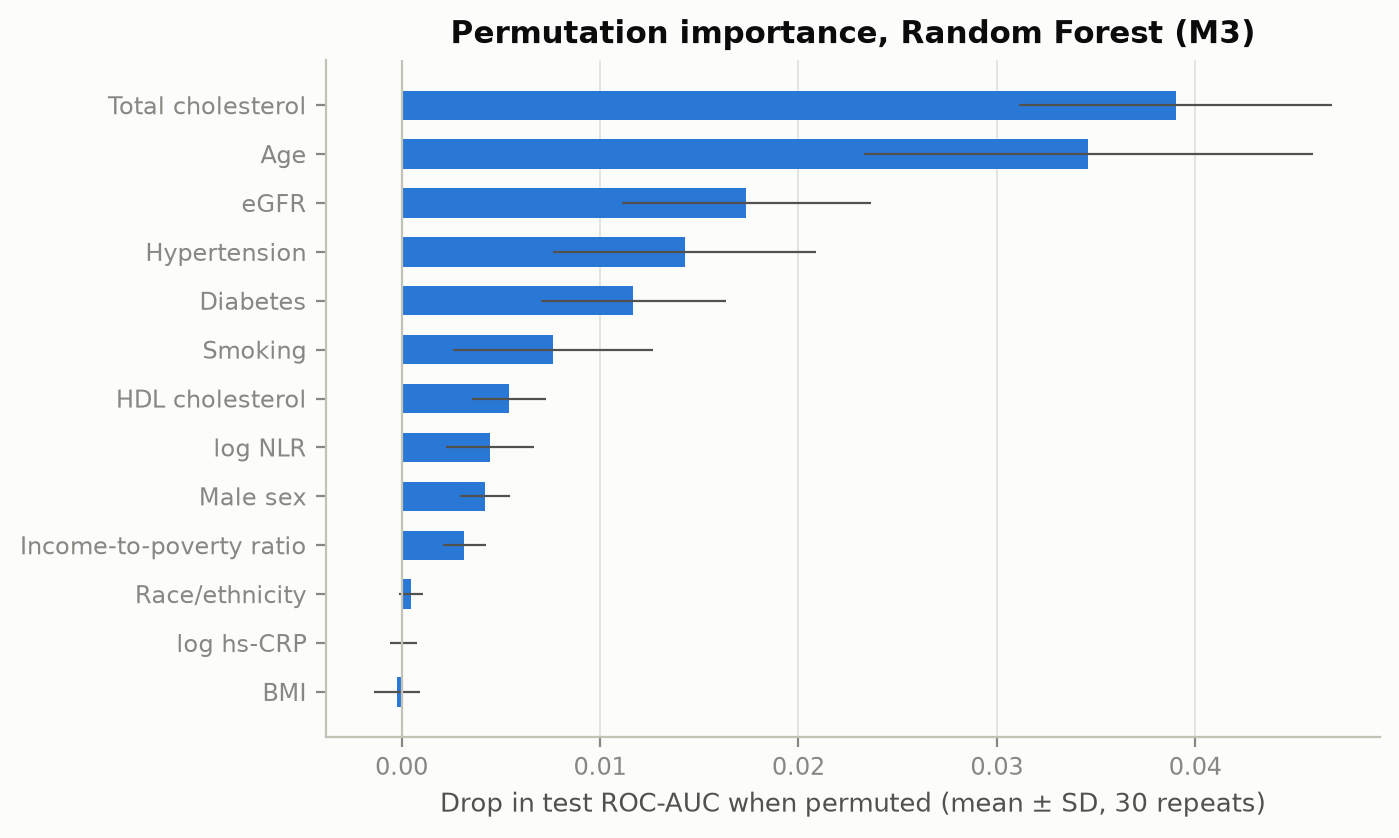

5. Partial Dependence der Entzündungsmarker:


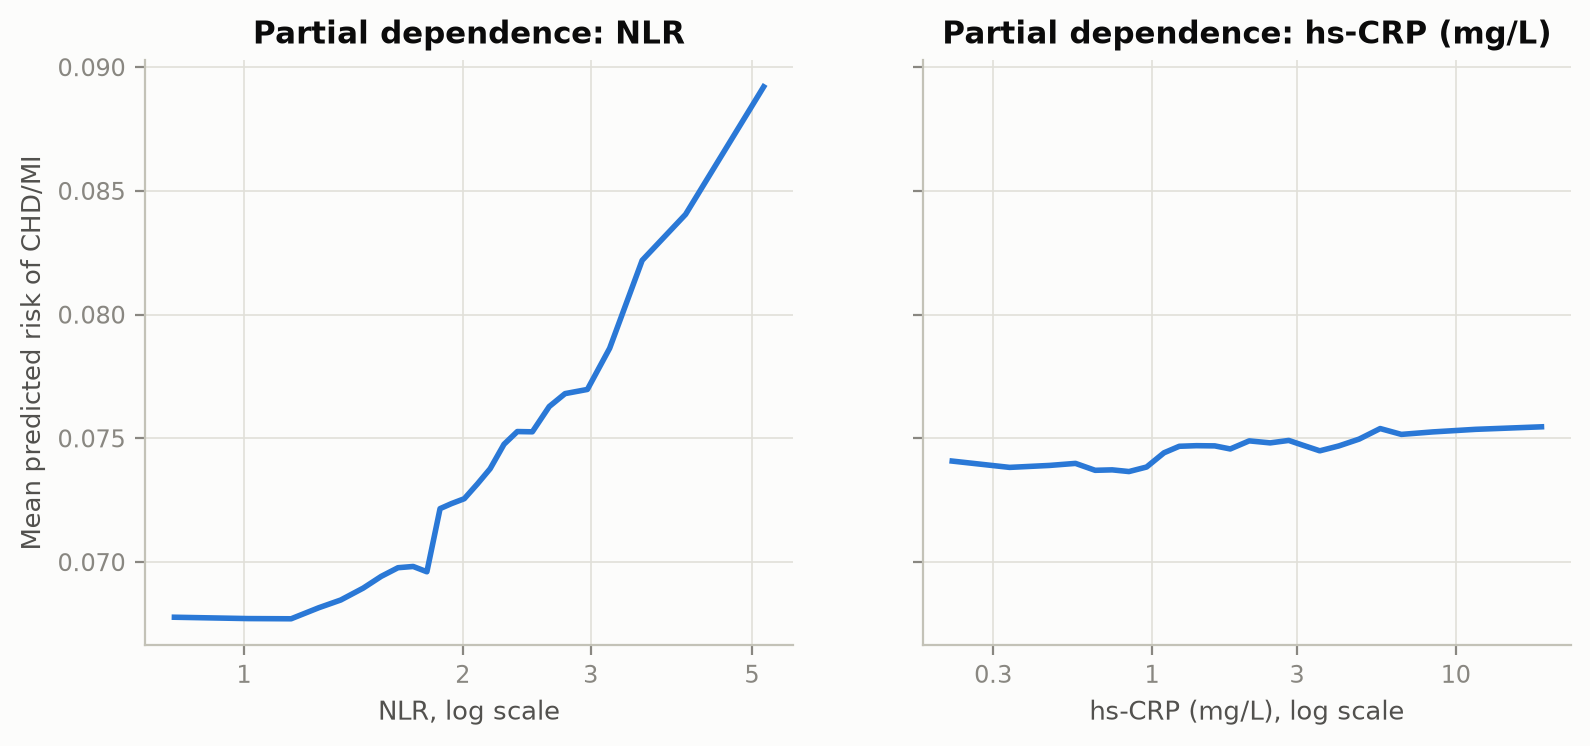

In [6]:
from IPython.display import Image, display

print("1. Diskrimination nach Feature-Set:")
display(Image(filename=str(FIG / "auc_by_feature_set.png")))

print("2. ROC- und Precision-Recall-Kurven (M2 vs. M3):")
display(Image(filename=str(FIG / "roc_pr_m2_m3.png")))

print("3. Kalibrierung M3 vs. Nullmodell:")
display(Image(filename=str(FIG / "calibration_m3.png")))

print("4. Permutation Feature Importance:")
display(Image(filename=str(FIG / "permutation_importance_m3.png")))

print("5. Partial Dependence der Entzündungsmarker:")
display(Image(filename=str(FIG / "partial_dependence_markers_m3.png")))